3) 지도학습 알고리즘 - 선형(선형결합)모델 회귀 LinearRegression

※ 선형 모델(Linear Model)은 입력 변수들의 선형결합(Linear Combination)을 이용해 예측값을 계산하는 모델

※ 활성화 함수는 선형결합으로 계산한 값을 변환하여 뉴런의 최종 출력을 결정하는 함수. 신경망에서 선형결합과 활성화 함수는 함께 사용된다. - 신경망 수업에서 설명

1. 선형선형결합
- 데이터의 관계를 직선으로 표현하고, 그 직선을 이용해 새로운 값을 예측하는 것
- 입력값 X와 결과값 y의 관계를 직선으로 표현하여 수치값을 예측하는 방법

여기서 선형모델은 y = ax + b 라는 직선을 찾는다. <br>
  x → 입력값, 공부시간 <br>
  y → 예측하려는 값, 시험점수 <br>
  a → 기울기 <br>
  b → 절편 <br>

2. KNN회귀모델 vs 선행회귀모델

| 구분 | KNN | 선형회귀 |
|---|---|---|
| 모델 | `KNeighborsRegressor` | `LinearRegression` |
| 학습 | 가까운 데이터 찾기 | 직선의 관계를 학습 |
| 예측 | 주변 이웃의 값 이용 | 학습한 직선으로 계산 |
| 주 용도 | 분류 / 회귀 | 회귀 |
| 대표 평가 | R² | R² |

3. LinerRegression 회귀

In [1]:
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. 데이터 생성
X, y = make_regression(
    n_samples=100,
    n_features=1,
    noise=10,
    random_state=42
)

# 2. 학습 / 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [2]:
# 3. 모델 생성
model = LinearRegression()

In [3]:
# 4. 학습
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[44.24]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.09922
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[8.09]


In [4]:
# 5. 예측
y_pred = model.predict(X_test)

In [5]:
# 6. 평가
r2 = r2_score(y_test, y_pred)

In [6]:
# 7. 출력
print("R²:", r2)

R²: 0.9374151607623286


In [7]:
print(model.coef_) # 기울기 y = ax + b의 a
print(model.intercept_) # 절편 y = ax + b의 b
# y = 44x + 0.09

[44.24418216]
0.09922221422587718


R²: 0.9374151607623286 <br>
[44.24418216] ->  coef_타입은 numpy.ndarray <br>
0.09922221422587718 -> intercept_속성은 실수타입 <br>
- intercept_속성은 항상 실수값 하나지만, coef_속성은 각 입력 특성에 하나씩 대응되는 NumPy배열이다. 예제에서는 입력변수가 하나뿐이므로 model.coef_도 하나의 원소만 가진다.
- coef_와 interceptor_를 모델이 찾은  파라미터라고 부른다. 사용자가 수정가능한 값은 하이퍼 파라미터라 부른다

- KNN 회귀는 학습하면서 기울기·절편 같은 수식을 만드는 모델이 아니다.
- 반면 LinearRegression은 학습하면서 가장 잘 맞는 직선의 기울기와 절편을 구한다.
-  model.predict()가 계산한 예측값을 연결하는 선(y = ax + b)을 추가
- 데이터의 실제값과 직선이 예측한 값의 차이를 잔차(residual)라고 한다.
- 오차(잔차) = 실제값 - 예측, 
- 선형회귀는 이 오차들을 전체적으로 작게 만드는 직선을 찾는다.
- 단순히 오차를 더하면 -,+값들이 서로 상쇄될 수 있어 
- 선형회귀에서는 일반적으로 오차를 제곱해서 모두 더한 값을 작게 만든다.
- 이를 최소제곱법(OLS)이라고 한다.
- 점들과 직선 사이의 오차가 전체적으로 작을수록 데이터를 잘 설명하는 직선이다.

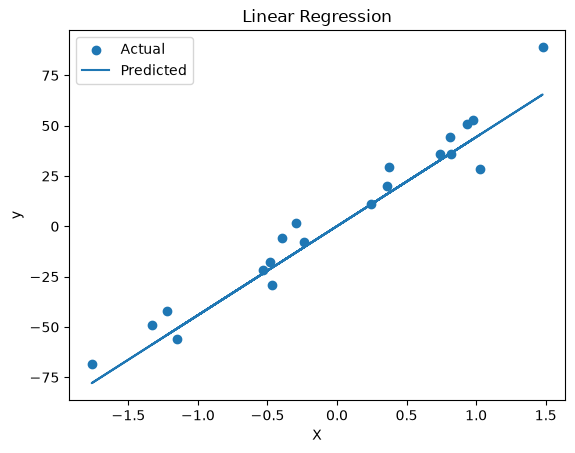

In [8]:
plt.scatter(X_test, y_test, label="Actual")
plt.plot(X_test, y_pred, label="Predicted") # y_pred는 직선의 예측치 이다.
plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression")
plt.legend()
plt.show()

seaborn의 regplot()함수를 이용하면 더 편하다

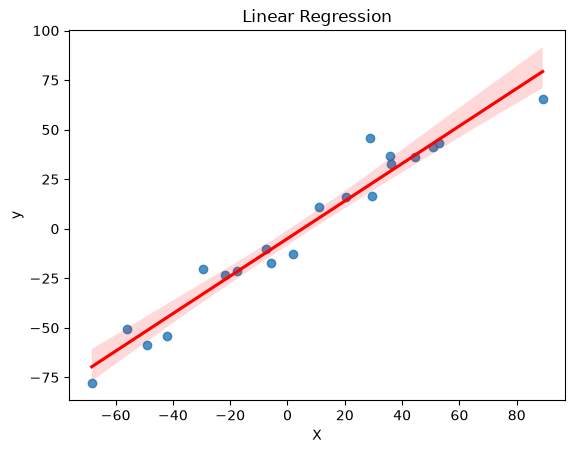

In [9]:
import seaborn as sns
sns.regplot(x=y_test, y=y_pred, line_kws={"color": "red"})
plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression")
plt.show()

4) 지도학습 알고리즘 - 선형모델 회귀(규제) Ridge, Rasso

1. 규제
- 모델이 훈련 세트에 과대적합되지 않도록 선형 회귀 모델의 경우 변수(특성)에 곱해지는 계수(기울기)의 크기를 작게 만든다.
- Ridge 회귀 : 계수를 작게 만든다.
- Rasso 회귀 : 계수를 작게 만든다. 일부 계수를 정확히 0으로 만들 수도 있다(불필요한 특성을 제거하는 효과)
- 두 모델은 sklearn.liner_model 패키지 안에 있다. 모델 객체를 만들때 alpha매개변수로 규제의 강도를 조절할 수 있다.
- alpha 값은 모델이 학습하면서 만들어 지는 파라미터가 아니고 사람이 설정하는 하이퍼파라미터이다.

```text
alpha ↑
→ 규제 강도 ↑
→ 계수를 더 강하게 축소
→ 너무 크면 과소적합

| `alpha` | 규제 강도 | 특징 |
|---:|---|---|
| `0` | 없음 | `LinearRegression`과 유사 |
| `0.1` | 약함 | 계수를 조금 줄임 |
| `1` | 보통 | 계수를 줄임 |
| `10` | 강함 | 계수를 많이 줄임 |
| `100` | 매우 강함 | 너무 강하면 과소적합 가능 |

In [1]:
import pandas as pd
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score

In [2]:
# 1. 데이터 생성 : 특성이 10개인데 실제로 중요한 특성은 2개 정도뿐인 데이터
X, y = make_regression(
    n_samples=30,
    n_features=10,       # 특성 10개
    n_informative=2,     # 실제로 중요한 특성은 2개, 8개는 y에 영향이 없는 변수
    noise=10,
    random_state=10
)

In [3]:
# 2. 훈련 / 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    random_state=42
)

In [4]:
# 3. LinearRegression
lr = LinearRegression()

lr.fit(X_train, y_train)

train_pred = lr.predict(X_train)
test_pred = lr.predict(X_test)

print("===== LinearRegression =====")
print("Train R2 :", r2_score(y_train, train_pred))
print("Test  R2 :", r2_score(y_test, test_pred))

===== LinearRegression =====
Train R2 : 0.8267517463869907
Test  R2 : 0.10844116291566797


In [5]:
# 4. Ridge
ridge = Ridge(alpha=10)

ridge.fit(X_train, y_train)

train_pred = ridge.predict(X_train)
test_pred = ridge.predict(X_test)

print()
print("===== Ridge =====")
print("Train R2 :", r2_score(y_train, train_pred))
print("Test  R2 :", r2_score(y_test, test_pred))


===== Ridge =====
Train R2 : 0.7046083917959967
Test  R2 : 0.5448625762676806


In [6]:
# 5. Lasso
lasso = Lasso(alpha=1)

lasso.fit(X_train, y_train)

train_pred = lasso.predict(X_train)
test_pred = lasso.predict(X_test)

print()
print("===== Lasso =====")
print("Train R2 :", r2_score(y_train, train_pred))
print("Test  R2 :", r2_score(y_test, test_pred))


===== Lasso =====
Train R2 : 0.7639177805382216
Test  R2 : 0.5704180499783369


#### 해석

규제 실습을 위해 생성한  데이터셋은 n_features=10, n_informative=2 로 특성은 10개인데 실제로 중요한 정보는 2개 정도만 있다. <br>
LinearRegression은 나머지 불필요한 특성까지 이용해서 X_train을 최대한 잘 설명하려고 한다. <br>
훈련 데이터에 너무 맞춰 학습된 상태 → 과적합 <br>

#### 규제 알고리즘 사용
훈련 데이터 성능을 조금 포기하고 → 새로운 데이터에 대한 일반화 성능을 높인다.

LinearRegression <br>
        ↓ <br>
Train 성능은 좋음 <br>
Test 성능은 나쁨 <br>
        ↓ <br>
과적합 <br>
        ↓ <br>
Ridge / Lasso 적용 <br>
        ↓ <br>
Train 성능은 조금 낮아질 수 있음 <br>
Test 성능은 좋아질 수 있음 <br>

In [7]:
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score


alphas = [0.01, 0.1, 1, 10, 100]

train_scores = []
test_scores = []


for alpha in alphas:

    model = Ridge(alpha=alpha)

    model.fit(X_train, y_train)

    # Train 예측
    train_pred = model.predict(X_train)

    # Test 예측
    test_pred = model.predict(X_test)

    # 결정계수
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    train_scores.append(train_r2)
    test_scores.append(test_r2)


# 결과 확인
display(pd.DataFrame({
    "alpha": alphas,
    "Train_R2": train_scores,
    "Test_R2": test_scores
}))

,alpha,Train_R2,Test_R2
0,0.01,0.826748,0.115485
1,0.10,0.826395,0.172323
2,1.00,0.812217,0.426846
3,10.00,0.704608,0.544863
4,100.00,0.304406,0.236820


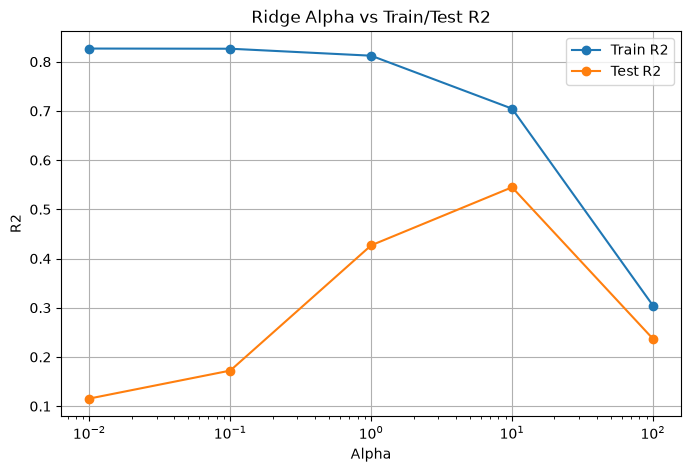

In [8]:
# 선차트
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(1, 1, 1)

ax.plot(alphas, train_scores, marker="o", label="Train R2")
ax.plot(alphas, test_scores, marker="o", label="Test R2")

# ax.set_xscale("log")는 x축을 로그 스케일로 표시
# x축 알파값의 간격이 [0.01, 0.1, 1, 10, 100]로 10배씩증가하기 때문에 
# 차트가 왼쪽의 간격은 좁고 오른쪽으로 갈수록 너무 많이 넓어져 차트의 가독성이 떨어진다.
# x축을 로그 스케일로 나타내면 10배씩 늘렸기 때문에 간격이 동일해 진다.
# 0.01 → 0.1   = ×10
# 0.1  → 1     = ×10
# 1    → 10    = ×10
# 10   → 100   = ×10
# alpha 계산 자체가 로그로 변하는 것은 아니다. 그래프의 축만 로그 스케일로 표시한다.

ax.set_xscale("log")

ax.set_xlabel("Alpha")
ax.set_ylabel("R2")
ax.set_title("Ridge Alpha vs Train/Test R2")

ax.legend()
ax.grid()

plt.show()

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score


alphas = [0.01, 0.1, 1, 10, 100]

train_scores = []
test_scores = []


for alpha in alphas:

    model = Lasso(alpha=alpha)

    model.fit(X_train, y_train)

    # Train
    train_pred = model.predict(X_train)

    # Test
    test_pred = model.predict(X_test)

    # R2
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    train_scores.append(train_r2)
    test_scores.append(test_r2)


# 결과 확인
display(pd.DataFrame({
    "alpha": alphas,
    "Train_R2": train_scores,
    "Test_R2": test_scores
}))

,alpha,Train_R2,Test_R2
0,0.01,0.826737,0.120514
1,0.10,0.825269,0.220333
2,1.00,0.763918,0.570418
3,10.00,0.137447,0.114869
4,100.00,0.000000,-0.026758


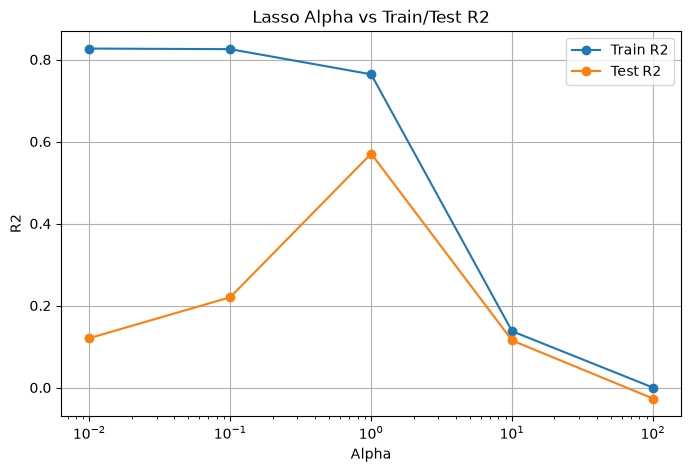

In [10]:
# 선차트
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(1, 1, 1)

ax.plot(alphas, train_scores, marker="o", label="Train R2")
ax.plot(alphas, test_scores, marker="o", label="Test R2")

# ax.set_xscale("log")는 x축을 로그 스케일로 표시
# x축 알파값의 간격이 [0.01, 0.1, 1, 10, 100]로 10배씩증가하기 때문에 
# 차트가 왼쪽의 간격은 좁고 오른쪽으로 갈수록 너무 많이 넓어져 차트의 가독성이 떨어진다.
# x축을 로그 스케일로 나타내면 10배씩 늘렸기 때문에 간격이 동일해 진다.
# 0.01 → 0.1   = ×10
# 0.1  → 1     = ×10
# 1    → 10    = ×10
# 10   → 100   = ×10
# alpha 계산 자체가 로그로 변하는 것은 아니다. 그래프의 축만 로그 스케일로 표시한다.

ax.set_xscale("log")

ax.set_xlabel("Alpha")
ax.set_ylabel("R2")
ax.set_title("Lasso Alpha vs Train/Test R2")

ax.legend()
ax.grid()

plt.show()